# Notebook 5 – Bivariate Analysis

**Definition:** Bivariate analysis studies the relationship between two variables.

**Simple example:** Compare study hours with test marks.

**Real-world example:** Study the relationship between outdoor temperature and electricity use.

**Business example:** Compare advertising spend with sales or department with salary.

**AI/ML use case:** Explore whether a feature may help predict a target and check for suspicious target leakage.

**Importance:** It reveals associations, group differences, clusters, and potential issues to investigate. Association alone does not prove causation.




## 1. Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.DataFrame({
    "employee_id": [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012],
    "age": [22, 25, 29, 31, 35, 41, 27, 38, 45, 24, np.nan, 31],
    "department": ["IT", "HR", "IT", "Sales", "IT", "Finance", "Sales", "HR", "Finance", "IT", "Sales", "it "],
    "education": ["Bachelor", "Master", "Bachelor", "Bachelor", "Master", "PhD", "Bachelor", "Master", "Bachelor", "Bachelor", "Master", "Bachelor"],
    "monthly_salary": [28000, 35000, 45000, 42000, 65000, 82000, 39000, 56000, 90000, 32000, 47000, 45000],
    "monthly_spending": [12000, 16000, 20000, 19000, 25000, 30000, 18000, 24000, 32000, 15000, 21000, 20000],
    "remote": ["No", "Yes", "Yes", "No", "Yes", "Yes", "No", "Yes", "No", "No", "Yes", "Yes"],
    "joined_date": pd.to_datetime(["2022-01-10", "2021-05-15", "2020-03-01", "2023-02-20", "2018-07-12", "2016-11-30", "2022-09-05", "2019-04-18", "2014-08-25", "2023-06-01", "2020-12-14", "2021-08-09"]),
    "left_company": ["No", "No", "No", "Yes", "No", "No", "Yes", "No", "No", "No", "Yes", "No"]
})
df


,employee_id,age,department,education,monthly_salary,monthly_spending,remote,joined_date,left_company
0,1001,22.0,IT,Bachelor,28000,12000,No,2022-01-10,No
1,1002,25.0,HR,Master,35000,16000,Yes,2021-05-15,No
2,1003,29.0,IT,Bachelor,45000,20000,Yes,2020-03-01,No
3,1004,31.0,Sales,Bachelor,42000,19000,No,2023-02-20,Yes
4,1005,35.0,IT,Master,65000,25000,Yes,2018-07-12,No
5,1006,41.0,Finance,PhD,82000,30000,Yes,2016-11-30,No
6,1007,27.0,Sales,Bachelor,39000,18000,No,2022-09-05,Yes
7,1008,38.0,HR,Master,56000,24000,Yes,2019-04-18,No
8,1009,45.0,Finance,Bachelor,90000,32000,No,2014-08-25,No
9,1010,24.0,IT,Bachelor,32000,15000,No,2023-06-01,No


## 2. Numerical vs Numerical
**Definition:** Both variables are numbers. A scatter plot displays paired values; correlation summarizes linear association from -1 to +1.

**Simple example:** Plot hours studied against exam score.

**Real-world example:** Plot daily temperature against electricity demand.

**Business example:** Plot advertising spending against sales revenue.

**AI/ML use case:** A feature strongly associated with a numeric target may be useful, but the relationship must be validated on training data and checked for leakage.

**Importance:** It helps identify trends, non-linear patterns, clusters, and outliers. Correlation does not prove that one variable causes the other.

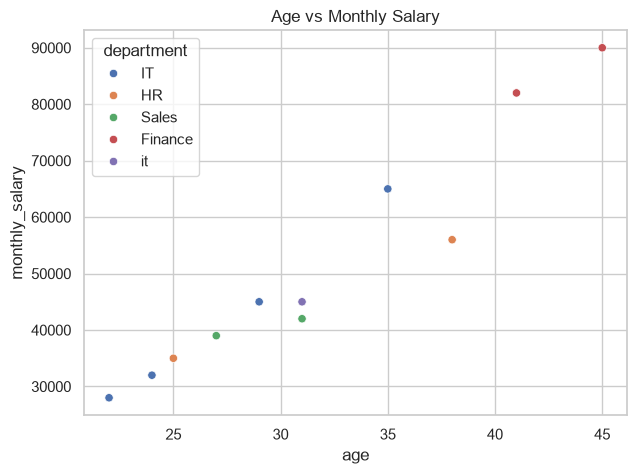

Pearson correlation: 0.963


In [2]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="age", y="monthly_salary", hue="department")
plt.title("Age vs Monthly Salary")
plt.show()
print("Pearson correlation:", round(df["age"].corr(df["monthly_salary"]), 3))

## 3. Numerical vs Categorical
**Definition:** One variable is numeric and the other represents groups. Compare distributions or summary statistics across groups.

**Simple example:** Compare marks by classroom.

**Real-world example:** Compare waiting times by hospital department.

**Business example:** Compare monthly salary or sales across departments/product categories.

**AI/ML use case:** Group differences may indicate a predictive signal, but fairness, confounding factors, and sample size should be considered.

**Importance:** Group means alone can hide spread and outliers, so inspect plots and sample counts together.

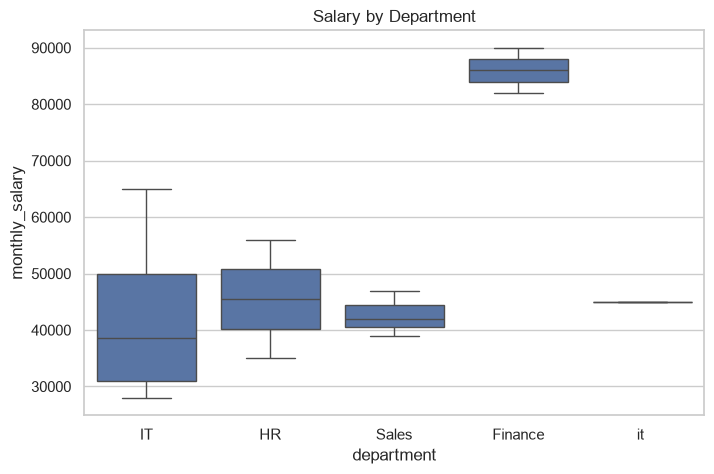

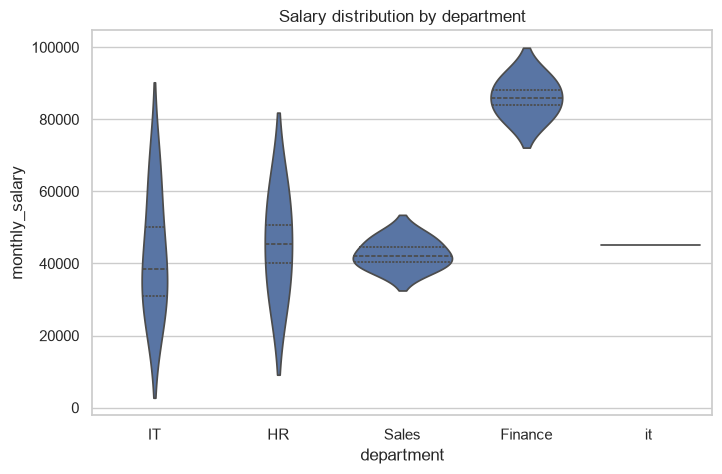

,count,mean,median,min,max
department,,,,,
Finance,2,86000.00,86000.0,82000,90000
HR,2,45500.00,45500.0,35000,56000
IT,4,42500.00,38500.0,28000,65000
Sales,3,42666.67,42000.0,39000,47000
it,1,45000.00,45000.0,45000,45000


In [3]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="department", y="monthly_salary")
plt.title("Salary by Department")
plt.show()

plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="department", y="monthly_salary", inner="quartile")
plt.title("Salary distribution by department")
plt.show()

display(df.groupby("department", dropna=False)["monthly_salary"].agg(["count", "mean", "median", "min", "max"]).round(2))

### Box Plot vs Violin Plot
A box plot summarizes quartiles and potential outliers. A violin plot adds a smoothed density shape. With very small groups, violin shapes can be unstable, so use them cautiously.

## 4. Categorical vs Categorical
**Definition:** Both variables are categories. Cross-tabulation counts combinations; grouped bars compare counts across groups.

**Simple example:** Count pass/fail outcomes by classroom.

**Real-world example:** Compare appointment type by clinic.

**Business example:** Compare product category by payment method or department by attrition status.

**AI/ML use case:** Check whether target rates differ across categories; this can inform feature exploration and fairness assessment.

**Importance:** Raw counts can be misleading when group sizes differ, so also examine row-wise proportions.

left_company,No,Yes
department,,
Finance,2,0
HR,2,0
IT,4,0
Sales,0,3
it,1,0


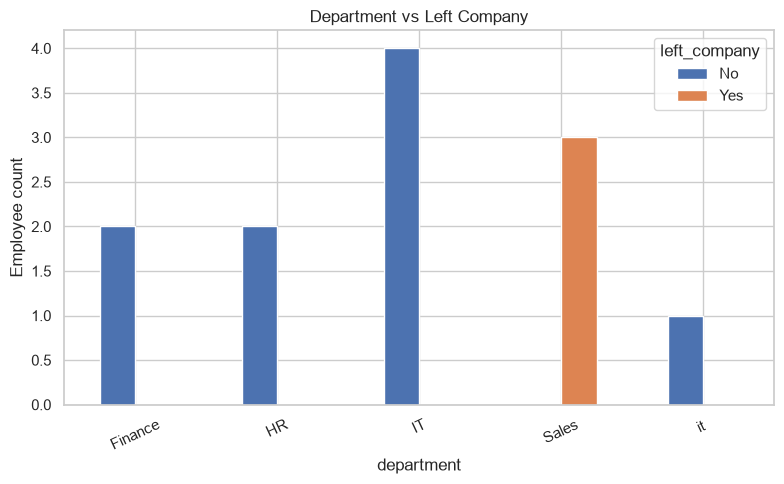

Row-wise proportions:


left_company,No,Yes
department,,
Finance,1.0,0.0
HR,1.0,0.0
IT,1.0,0.0
Sales,0.0,1.0
it,1.0,0.0


In [4]:
cross_tab = pd.crosstab(df["department"], df["left_company"])
display(cross_tab)
cross_tab.plot(kind="bar", figsize=(8, 5))
plt.title("Department vs Left Company")
plt.ylabel("Employee count")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print("Row-wise proportions:")
display(pd.crosstab(df["department"], df["left_company"], normalize="index").round(2))

## 5. Grouped Bar Chart and Cross Tabulation
**Definition:** A grouped bar chart displays category counts or summaries side by side. A cross-tabulation table counts the combinations of two categorical variables.

**Business example:** A store compares sales orders by product category and payment type.

**AI/ML use case:** Compare target proportions by customer segment; investigate whether a feature may carry useful information or introduce fairness concerns.

**Importance:** Use counts and percentages together, and remember small samples can produce unstable patterns.

## 6. Interpret relationships carefully
A visible pattern can be caused by a third variable, selection bias, or a small sample. Confirm observations with domain knowledge and appropriate statistical methods. Avoid statements like “age causes salary to rise” based only on a scatter plot.

## 7. How bivariate findings affect an ML pipeline
- Candidate features may be investigated further.
- Highly correlated numeric features may be redundant for some models.
- Strong feature-target relationships should be checked for target leakage.
- Group differences may suggest feature engineering, but fairness and causal interpretation need care.
- Keep final model decisions based on training/validation data, not the test set.